---
title: "The next six pentads, October-December 2023"
subtitle: "Subseasonal rainfall forecasts for Indonesia at 0.05°, from GEFSv12 issued at the end of each pentad and calibrated with CCA and PCR through CPT"
description: "Forecast total rainfall for the next one to six pentads from each issue date in late 2023, using GEFSv12 calibrated with CCA and PCR against the CHIRPS v3.0 pentad product at its native 0.05° grid, and measure skill by lead over 2000-2018."
execute:
  enabled: false
---

A pentad is CHIRPS's shortest standard period: days 1-5, 6-10, 11-15, 16-20,
21-25 and 26 to the end of each month, six per month. Here a forecast is issued on
the **last day of each pentad**, from the GEFSv12 run started at 00 UTC that day,
and gives the **total rainfall of each of the next six pentads**, about a month
ahead in five-day steps.

The forecasts are calibrated against the **CHIRPS v3.0 pentad product at its native
0.05° grid**, about 61,000 pixels over Indonesia. CHC builds daily CHIRPS by sharing
each pentad's amount between its days with ERA5 or IMERG timing and recommends
pentadal or longer totals wherever the science allows, so this case reads the pentads
themselves rather than adding up days. The design (issue
rule, lead windows, model, years, settings, scores) was fixed before any skill was
computed.

::: {.callout-note title="What you need to run this page"}
The full PyCPT environment with its CPT engine; the CHIRPS v3.0 **pentad** product
for Indonesia as yearly NetCDF files (exported from Earth Engine and converted by the
tutorial's `gee_pentad_to_netcdf.py`); and internet
access the first time for about 330 GEFSv12 files from the IRI Data Library, no
key needed. At 0.05° one CPT fit takes hours, so the twelve fits run in parallel,
one process each, and need about 12 free CPU cores and 40 GB of disk.
:::

## 1. Issue dates, leads and training starts

**In real time** a forecast is issued on the last day of a pentad. Pentad +1 begins
the next day; pentad +k begins after the k-1 pentads before it, 5 days each except
the last pentad of a month (3 to 6 days). GEFSv12 runs every day, so the 2023
forecasts use exactly these issue dates.

**For training**, GEFSv12's hindcasts (2000-2018) start only on Wednesdays. For each
October-December target pentad and each lead, the training sample uses the one
Wednesday whose start falls in a 7-day window around the real-time offsets of that
lead. Every 7-day window holds exactly one Wednesday, so all six leads are trained
on the same 342 target pentads (18 per year) and scored on the same targets. As in
the dekad case, training starts are on average a little further from the target than
real-time ones, most for pentad +1 (1-7 days against 1 day). The design comes from
the tutorial's
[pentad GEFS download script](https://github.com/bennyistanto/pycpt-tutorial/blob/main/research/scripts/download_gefs_pentads.py),
which the cell imports and checks: every 2023 offset lies inside its window, and no
target needs a model day beyond 34.

One 2023 run is unusable: the IRI Data Library's GEFSv12 forecast started on
5 December 2023 holds only missing values, in every member and day, also after a
fresh download. As a forecaster would, the forecast issued that day uses the latest
complete run, 4 December 00 UTC; its offsets are one day longer and still inside every
training window.

In [1]:
from pathlib import Path
import datetime as dt
import gzip
import json
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
import xarray as xr
import cartopy.io.shapereader as shapereader

repo = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pycpt_tutorial").is_dir()), None)
if repo is None:
    raise FileNotFoundError("Run this notebook inside the tutorial repository or kit.")
sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "research/scripts"))
from pycpt_tutorial.export import save_netcdf
from pycpt_tutorial import figures
import download_gefs_dekads as gefs_source      # request, check and download helpers
import download_gefs_pentads as pentads         # the pentad design
import weekly_fits                              # parallel CPT fits (shared with the weekly case)
figures.use_style()

case_root = Path.home() / "PyCPT" / "indonesia-ond-2023-pentads"
daily_dir = Path("/mnt/e/temp/chirps/daily-idn")
leads = list(pentads.WINDOWS)                    # 1 to 6
lead_names = {lead: f"Pentad +{lead}" for lead in leads}
training_years = list(pentads.TRAINING_YEARS)
settings = dict(x_eof_modes=(3, 3), validation="CROSSVALIDATION", crossvalidation_window=35,
                synchronous_predictors=True, transform_predictand=None, tailoring=None,
                drymask_threshold=None, skillmask_threshold=None)
cca_settings = dict(settings, y_eof_modes=(3, 3), cca_modes=(2, 2))
workers = 12

pentads.check_design()
design = pd.DataFrame(pentads.design()).rename(columns={"pentad": "target"})
for c in ["target", "end", "issued", "start"]:
    design[c] = pd.to_datetime(design[c])
substituted = design[(design.kind == "forecast") & (design.issued != design.start)].drop_duplicates("issued")
print("Issue dates using an earlier run:", {f"{r.issued:%d %b %Y}": f"run of {r.start:%d %b %Y}" for r in substituted.itertuples()})
print(f"{design[design.kind == 'hindcast'].start.nunique()} hindcast starts, {design[design.kind == 'forecast'].issued.nunique()} issue dates in 2023; "
      f"target lengths (days): {design[design.lead == 1].days.value_counts().sort_index().to_dict()}")
table = (design.groupby(["kind", "lead"])
         .agg(targets=("target", "size"), first_offset=("first_day", "min"), last_offset=("first_day", "max"), latest_model_day=("last_day", "max")))
table["training window (days)"] = [f"{pentads.WINDOWS[lead][0]}-{pentads.WINDOWS[lead][1]}" for _, lead in table.index]
table

Issue dates using an earlier run: {'05 Dec 2023': 'run of 04 Dec 2023'}
311 hindcast starts, 23 issue dates in 2023; target lengths (days): {5: 320, 6: 40}


targets  first_offset  last_offset  latest_model_day  \
kind     lead                                                         
forecast 1          18             1            2                 6   
         2          18             6            7                11   
         3          18            11           12                16   
         4          18            16           17                21   
         5          18            21           22                27   
         6          18            26           27                31   
hindcast 1         342             1            7                12   
         2         342             3            9                14   
         3         342             8           14                19   
         4         342            13           19                24   
         5         342            18           24                29   
         6         342            23           29                34   

              training window (days)  
kind     lead                         
forecast 1                       1-7  
         2                       3-9  
         3                      8-14  
         4                     13-19  
         5                     18-24  
         6                     23-29  
hindcast 1                       1-7  
         2                       3-9  
         3                      8-14  
         4                     13-19  
         5                     18-24  
         6                     23-29

## 2. Observations: CHIRPS v3.0 pentads at 0.05°

Each yearly file holds the 72 CHIRPS pentads, with their first and last day stored as
time bounds. The cell checks that every October-December target in the design is one
of those pentads, with the same first day and length, before using it. The
predictand is every 0.05° pixel whose centre lies inside Indonesia (Natural Earth
1:10m) with data in all training pentads.

In [2]:
pentad_dir = Path("/mnt/e/temp/chirps/pentad-idn")
years = sorted(set(design.year))
files = [pentad_dir / f"chirps3_pentad_idn_{y}.nc" for y in years]
assert all(f.exists() for f in files), [f.name for f in files if not f.exists()]
source = xr.open_mfdataset(files, combine="by_coords")
print("Attributes:", {k: source.precip.attrs[k] for k in ("units", "cell_methods", "long_name")})

targets = design[design.lead == 1].sort_values("target").reset_index(drop=True)
for lead in leads:                               # every lead uses the same target pentads
    assert (design[design.lead == lead].sort_values("target").target.values == targets.target.values).all()
stored = pd.DatetimeIndex(source.time_bnds.sel(time=targets.target.values).values.ravel()).values.reshape(-1, 2)
assert (stored[:, 0] == targets.target.values).all() and (stored[:, 1] == targets.end.values).all()
print(f"All {len(targets)} target pentads found, with stored bounds equal to the design")

start = time.monotonic()
obs = (source.precip.sel(time=targets.target.values).load().rename({"time": "T", "lat": "Y", "lon": "X"})
       .sortby("Y", ascending=False))
print(f"Read {dict(obs.sizes)} in {time.monotonic() - start:.0f} s; negative values: {int((obs < 0).sum())}")

records = shapereader.Reader(shapereader.natural_earth("10m", "cultural", "admin_0_countries")).records()
indonesia = next(r.geometry for r in records if r.attributes["ADM0_A3"] == "IDN")
shapely.prepare(indonesia)
lon2d, lat2d = np.meshgrid(obs.X, obs.Y)
land = xr.DataArray(shapely.contains_xy(indonesia, lon2d, lat2d), dims=("Y", "X"), coords={"Y": obs.Y, "X": obs.X})
train = (targets.kind == "hindcast").values
mask = land & obs.isel(T=train).notnull().all("T")
weights = np.cos(np.deg2rad(mask["Y"])) * mask
print(f"Pixels inside Indonesia {int(land.sum()):,}, with data in every training pentad {int(mask.sum()):,}")

Attributes: {'units': 'mm', 'cell_methods': 'time: sum', 'long_name': 'CHIRPS v3.0 pentad precipitation total'}


All 360 target pentads found, with stored bounds equal to the design


Read {'T': 360, 'Y': 381, 'X': 961} in 10 s; negative values: 0


Pixels inside Indonesia 61,192, with data in every training pentad 61,190


Two checks against the other CHIRPS v3.0 files of the tutorial. Two pentads make a
dekad, so their sum should equal the dekadal archive. And the daily files of the
weekly case, added up over each target pentad, should give back the pentad amount
if daily values only share it between days; the cell measures how far they are
from it over all 342 training pentads.

In [3]:
dekads = xr.open_dataset("/mnt/e/temp/chirps/dekad/wld_cli_chirps3_dekad_1981_2025.nc")
by_first = {pd.Timestamp(t): k for k, t in enumerate(obs["T"].values)}
for first, second in [("2005-10-01", "2005-10-06"), ("2012-11-11", "2012-11-16"), ("2023-12-21", "2023-12-26")]:
    two = obs.isel(T=by_first[pd.Timestamp(first)]) + obs.isel(T=by_first[pd.Timestamp(second)])
    archive = (dekads.precip.sel(time=first).reindex(lat=obs.Y.values, lon=obs.X.values, method="nearest", tolerance=1e-3)
               .rename({"lat": "Y", "lon": "X"}).load())
    gap = abs(two - archive).where(land)
    print(f"pentads {first} + {second} vs dekad {first}, Indonesian pixels: largest difference {float(gap.max()):.4f} mm, "
          f"same missing pixels: {not bool(((two.isnull() != archive.isnull()) & land).any())}")

daily_dir = Path("/mnt/e/temp/chirps/daily-idn")
daily = xr.open_mfdataset([daily_dir / f"chirps3_rnl_daily_idn_{y}.nc" for y in years], combine="by_coords").precip
largest, mean_abs = 0.0, []
for r in targets[targets.kind == "hindcast"].itertuples():
    days = daily.sel(time=slice(r.target, r.end - pd.Timedelta(days=1)))
    assert days.sizes["time"] == r.days
    summed = days.sum("time", skipna=False).load().rename({"lat": "Y", "lon": "X"}).reindex_like(obs)
    gap = abs(summed - obs.sel(T=r.target)).where(mask)
    largest = max(largest, float(gap.max()))
    mean_abs.append(float(gap.mean()))
print(f"Summed daily rnl vs pentad product, 342 training pentads, Indonesian pixels: largest difference {largest:.4f} mm, "
      f"mean absolute difference {np.mean(mean_abs):.5f} mm")

pentads 2005-10-01 + 2005-10-06 vs dekad 2005-10-01, Indonesian pixels: largest difference 0.0000 mm, same missing pixels: True


pentads 2012-11-11 + 2012-11-16 vs dekad 2012-11-11, Indonesian pixels: largest difference 0.0000 mm, same missing pixels: True


pentads 2023-12-21 + 2023-12-26 vs dekad 2023-12-21, Indonesian pixels: largest difference 0.0000 mm, same missing pixels: True


Summed daily rnl vs pentad product, 342 training pentads, Indonesian pixels: largest difference 0.0001 mm, mean absolute difference 0.00000 mm


## 3. Model: daily GEFSv12 to pentad totals

Each start is one request to the IRI Data Library for the predictor box
85-155°E, 20°S-20°N, all members and daily slots; files already on disk are reused
when they cover every model day their targets need (most were downloaded for the
dekad and weekly cases). Hindcasts store each day's amount (kg m⁻², which is mm),
real-time forecasts a rate (kg m⁻² s⁻¹), converted with 86,400 seconds per day.
Model day d after the start is slot L = d + 0.5. A pentad total is the sum of the
target's days, then the mean over members.

In [4]:
raw_dir = case_root.parent / "indonesia-ond-2023-dekads" / "gefs"
need = pentads.needed_starts()
fetched = sum(gefs_source.ensure(raw_dir, kind, s, last_day) > 0 for (kind, s), last_day in need.items())
print(f"{len(need)} starts checked; downloaded now: {fetched}")

factor = {"hindcast": 1.0, "forecast": 86400.0}
totals, missing, negative = {}, 0, 0
for (kind, s), rows in design.groupby(["kind", "start"]):
    with xr.open_dataset(gefs_source.path_for(raw_dir, kind, s.date()), decode_timedelta=False) as ds:
        pr = ds["pr"].isel(S=0, drop=True).load()
    for r in rows.itertuples():
        d = pr.sel(L=np.arange(r.first_day, r.first_day + r.days) + 0.5)
        missing += int((~np.isfinite(d)).sum())
        negative += int((d < 0).sum())
        totals[r.lead, r.target] = (d * factor[kind]).sum("L", skipna=False).mean("M", skipna=False)
assert missing == 0 and negative == 0
gefs = {lead: xr.concat([totals[lead, t] for t in targets.target], "T").assign_coords(T=targets.target.values)
        .sortby("Y", ascending=False) for lead in leads}
print(f"GEFS totals per lead {dict(gefs[1].sizes)}; missing values {missing}, negative values {negative}")

334 starts checked; downloaded now: 0


GEFS totals per lead {'T': 360, 'Y': 41, 'X': 71}; missing values 0, negative values 0


## 4. Anomalies, and what CPT needs

Rainfall rises through October-December, so model and observations are turned into
**anomalies** from the 2000-2018 mean of the **same calendar pentad** (and, for the
model, the same lead), as the dekad case does per calendar dekad. The same means are
subtracted from the 2023 values, and the observed mean is added back at the end to
give a forecast **total**. These means include the year held out in
cross-validation; for correlations that makes no difference (leaving a year out
multiplies every anomaly of that pentad by the same factor, 19/18), and its effect
inside CPT's fits was not measured.

CPT needs the same three adjustments as in the dekad case: placeholder annual dates
in the original order (cross-validation depends only on the order), the field name
`anomaly` (CPT refuses negative values under precipitation names), and latitudes
from north to south. The cross-validation window of 35 leaves out the held-out
pentad and 17 on each side, about a whole season, so a training fit never sees
another pentad of the same season.

In [5]:
key = pd.DatetimeIndex(targets.target).strftime("%m-%d")
train_keys = key[train]
W = np.zeros((len(key), int(train.sum())))
for i, k in enumerate(key):
    same = np.flatnonzero(train_keys == k)
    W[i, same] = 1 / len(same)
assert ((W > 0).sum(1) == len(training_years)).all()


def apply_weights(field):
    a = field.isel(T=train).transpose("T", ...).values
    clim = (W @ np.nan_to_num(a.reshape(a.shape[0], -1))).reshape((W.shape[0],) + a.shape[1:])
    return field.copy(data=clim.astype("float32"))


y_clim = apply_weights(obs).where(mask)
y_anom = (obs - y_clim).where(mask)
x_anom = {lead: gefs[lead] - apply_weights(gefs[lead]) for lead in leads}
area = lambda f: float(f.where(mask).weighted(weights).mean(("Y", "X")))
season = y_clim.isel(T=np.flatnonzero(train)[:18]).weighted(weights).mean(("Y", "X"))
print("2000-2018 mean pentad rainfall over Indonesian pixels (mm):",
      dict(zip(key[:18], np.round(season.values, 1).tolist())))


def cpt_ready(a, first_year):
    years = first_year + np.arange(a.sizes["T"])
    a = a.drop_vars([c for c in a.coords if c not in ("T", "Y", "X")]).transpose("T", "Y", "X")
    a = a.assign_coords(T=pd.to_datetime([f"{y}-10-03" for y in years]),
                        Ti=("T", pd.to_datetime([f"{y}-10-01" for y in years])),
                        Tf=("T", pd.to_datetime([f"{y}-10-05" for y in years])))
    a = a.rename("anomaly")
    a.attrs = {"units": "mm", "missing": -999.0}
    return a


inputs_dir = case_root / "inputs"
inputs_dir.mkdir(parents=True, exist_ok=True)
paths = {"Y": inputs_dir / "Y.nc"}
cpt_ready(y_anom.isel(T=train), 1680).to_netcdf(paths["Y"])
for lead in leads:
    paths["X", lead] = inputs_dir / f"X-lead{lead}.nc"
    paths["F", lead] = inputs_dir / f"F-lead{lead}.nc"
    cpt_ready(x_anom[lead].isel(T=train), 1680).to_netcdf(paths["X", lead])
    cpt_ready(x_anom[lead].isel(T=~train), 2040).to_netcdf(paths["F", lead])
print({str(k): f"{p.stat().st_size / 1e6:.0f} MB" for k, p in paths.items()})

2000-2018 mean pentad rainfall over Indonesian pixels (mm): {'10-01': 36.7, '10-06': 38.5, '10-11': 36.3, '10-16': 38.8, '10-21': 41.8, '10-26': 51.7, '11-01': 44.4, '11-06': 44.8, '11-11': 48.4, '11-16': 49.8, '11-21': 47.4, '11-26': 51.5, '12-01': 50.1, '12-06': 48.7, '12-11': 50.5, '12-16': 47.0, '12-21': 50.2, '12-26': 61.3}


{'Y': '501 MB', "('X', 1)": '4 MB', "('F', 1)": '0 MB', "('X', 2)": '4 MB', "('F', 2)": '0 MB', "('X', 3)": '4 MB', "('F', 3)": '0 MB', "('X', 4)": '4 MB', "('F', 4)": '0 MB', "('X', 5)": '4 MB', "('F', 5)": '0 MB', "('X', 6)": '4 MB', "('F', 6)": '0 MB'}


## 5. Twelve fits, in parallel

CCA (3 predictor and 3 predictand EOFs, 2 CCA modes) and PCR (3 predictor EOFs) for
each of the six leads, through `cptcore`, the layer PyCPT's `evaluate_models`
calls. Each fit runs in its own process (`weekly_fits.py` in the tutorial's research
scripts, shared with the weekly case) and keeps only the forecast and skill maps; a
fit is reused only if its saved result was made from identical input values and
settings. Each worker also recomputes the correlation from CPT's own cross-validated
hindcasts and stores the largest difference from CPT's map.

In [6]:
jobs = [dict(lead=lead, method=method, folder=str(case_root / f"fit-lead{lead}-{method.lower()}"),
             inputs={"X": str(paths["X", lead]), "Y": str(paths["Y"]), "F": str(paths["F", lead])},
             settings=cca_settings if method == "CCA" else settings)
        for lead in leads for method in ["CCA", "PCR"]]
start = time.monotonic()
done = weekly_fits.run_all(jobs, workers=workers)
print(f"All fits finished in {(time.monotonic() - start) / 60:.0f} min wall time")
results, rows = {}, []
for d in done:
    r = xr.open_dataset(d["path"]).load()
    results[d["lead"], d["method"]] = r
    rows.append({"lead": lead_names[d["lead"]], "method": d["method"], "fit (min)": round(r.attrs["fit_seconds"] / 60, 1),
                 "reused": d["reused"], "hindcast values below 0 (%)": round(r.attrs["hindcast_values_below_zero_percent"], 1),
                 "largest gap, CPT vs recomputed correlation": r.attrs["largest_gap_cpt_vs_recomputed_pearson"]})
pd.DataFrame(rows).set_index(["lead", "method"])

All fits finished in 0 min wall time


fit (min)  reused  hindcast values below 0 (%)  \
lead      method                                                   
Pentad +1 CCA         234.7    True                         51.5   
          PCR          43.3    True                         51.2   
Pentad +2 CCA         184.1    True                         51.8   
          PCR          43.7    True                         51.6   
Pentad +3 CCA         186.5    True                         51.1   
          PCR          43.0    True                         51.3   
Pentad +4 CCA         230.9    True                         51.7   
          PCR          43.4    True                         51.9   
Pentad +5 CCA         232.9    True                         52.0   
          PCR          49.2    True                         52.0   
Pentad +6 CCA         230.9    True                         51.6   
          PCR          48.6    True                         51.7   

                  largest gap, CPT vs recomputed correlation  
lead      method                                              
Pentad +1 CCA                                   7.718372e-07  
          PCR                                   7.845513e-07  
Pentad +2 CCA                                   7.745501e-07  
          PCR                                   8.072504e-07  
Pentad +3 CCA                                   7.917359e-07  
          PCR                                   7.254360e-07  
Pentad +4 CCA                                   7.330984e-07  
          PCR                                   7.433207e-07  
Pentad +5 CCA                                   8.109644e-07  
          PCR                                   7.764674e-07  
Pentad +6 CCA                                   7.692573e-07  
          PCR                                   7.330110e-07

Negative hindcast values show the anomalies were not clipped at zero, and a gap near
zero shows CPT's correlation map is the correlation of its own cross-validated
hindcasts.

## 6. Skill by lead

Cross-validated scores over the 342 training pentads, as area-weighted means over
the Indonesian pixels (weights: cosine of latitude):

- **Pearson correlation** of hindcast and observed anomalies; 0 is no linear relationship.
- **2AFC**: the chance (in %) that the hindcasts rank two different pentads in the observed order; 50% is no skill.
- **ROC area** for below- and above-normal pentads; 0.5 is no skill.

The **raw GEFS** baseline is the model's own anomaly, interpolated linearly from 1°
to the pixel centres, correlated with the observed anomalies. It involves no
fitting, so it pays none of the cost that cross-validation charges the calibrated
forecasts.

In [7]:
def clean(a):
    return a.where(a > -999).reindex(Y=mask["Y"], X=mask["X"], method="nearest", tolerance=1e-4).where(mask)


def pearson(a, b):
    a, b = a - a.mean("T"), b - b.mean("T")
    return (a * b).sum("T") / np.sqrt((a * a).sum("T") * (b * b).sum("T"))


raw_pearson = {}
for lead in leads:
    xa = x_anom[lead].isel(T=train).interp(Y=mask["Y"], X=mask["X"], method="linear")
    raw_pearson[lead] = pearson(xa, y_anom.isel(T=train)).where(mask)

rows = []
for (lead, method), r in results.items():
    rows.append({"lead": lead, "name": lead_names[lead], "method": method,
                 "Pearson": area(clean(r.skill_pearson)), "2AFC (%)": area(clean(r.skill_two_alternative_forced_choice)),
                 "ROC below normal": area(clean(r.skill_roc_area_below_normal)), "ROC above normal": area(clean(r.skill_roc_area_above_normal))})
for lead in leads:
    rows.append({"lead": lead, "name": lead_names[lead], "method": "raw GEFS", "Pearson": area(raw_pearson[lead])})
skill_by_lead = pd.DataFrame(rows).set_index(["lead", "method"]).sort_index()
skill_by_lead.round(3)

name  Pearson  2AFC (%)  ROC below normal  \
lead method                                                     
1    CCA       Pentad +1    0.297    61.003             0.667   
     PCR       Pentad +1    0.302    61.234             0.670   
     raw GEFS  Pentad +1    0.415       NaN               NaN   
2    CCA       Pentad +2    0.293    60.528             0.659   
     PCR       Pentad +2    0.296    60.751             0.662   
     raw GEFS  Pentad +2    0.373       NaN               NaN   
3    CCA       Pentad +3    0.242    58.948             0.635   
     PCR       Pentad +3    0.242    59.035             0.636   
     raw GEFS  Pentad +3    0.269       NaN               NaN   
4    CCA       Pentad +4    0.228    58.611             0.635   
     PCR       Pentad +4    0.226    58.548             0.633   
     raw GEFS  Pentad +4    0.214       NaN               NaN   
5    CCA       Pentad +5    0.173    56.995             0.610   
     PCR       Pentad +5    0.175    57.002             0.610   
     raw GEFS  Pentad +5    0.165       NaN               NaN   
6    CCA       Pentad +6    0.121    55.501             0.592   
     PCR       Pentad +6    0.130    55.597             0.589   
     raw GEFS  Pentad +6    0.129       NaN               NaN   

               ROC above normal  
lead method                      
1    CCA                  0.654  
     PCR                  0.658  
     raw GEFS               NaN  
2    CCA                  0.647  
     PCR                  0.651  
     raw GEFS               NaN  
3    CCA                  0.625  
     PCR                  0.627  
     raw GEFS               NaN  
4    CCA                  0.620  
     PCR                  0.620  
     raw GEFS               NaN  
5    CCA                  0.597  
     PCR                  0.597  
     raw GEFS               NaN  
6    CCA                  0.573  
     PCR                  0.577  
     raw GEFS               NaN

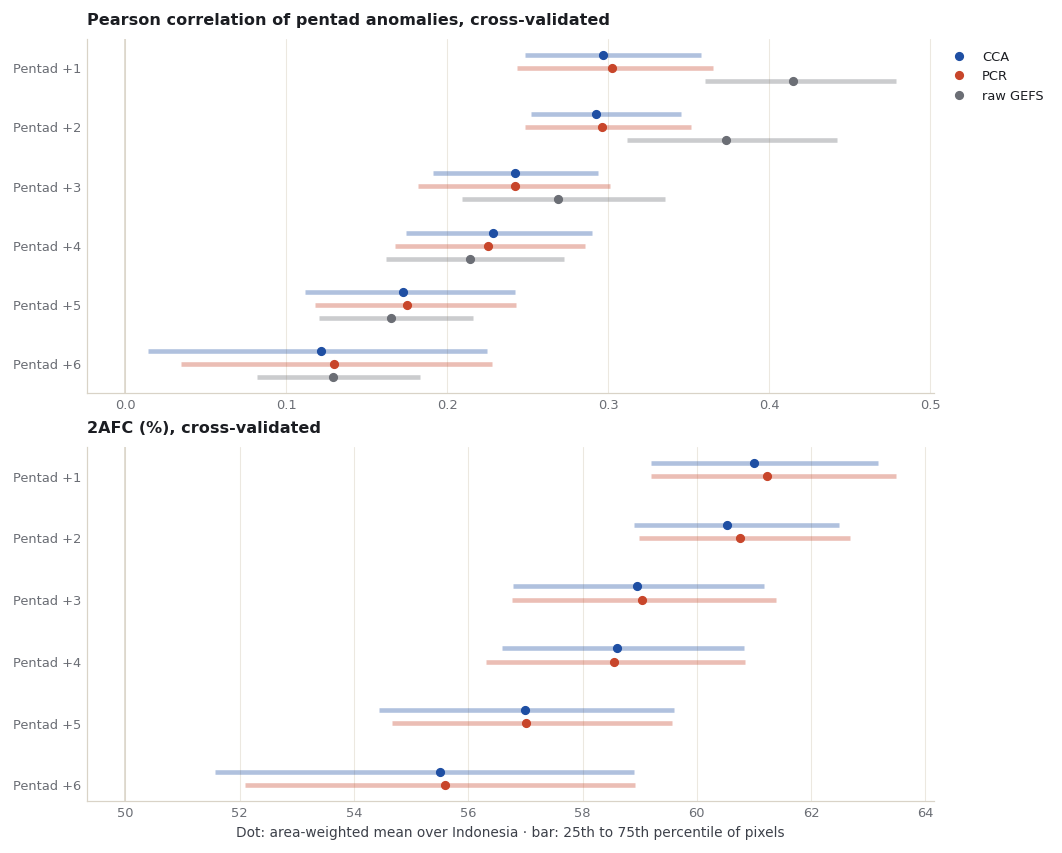

In [8]:
def quartiles(field):
    return np.nanpercentile(field.where(mask).values, [25, 75])


series = {"CCA": figures.ACCENT, "PCR": figures.MARK, "raw GEFS": figures.MUTED}
panels = [("Pearson", "skill_pearson", "Pearson correlation of pentad anomalies, cross-validated", 0),
          ("2AFC (%)", "skill_two_alternative_forced_choice", "2AFC (%), cross-validated", 50)]
fig, axes = plt.subplots(len(panels), 1, figsize=(figures.MAP_WIDTH, 7.6), layout="constrained")
for ax, (column, metric, title, reference) in zip(axes, panels):
    ax.axvline(reference, color=figures.LINE, linewidth=1)
    for k, (method, colour) in enumerate(series.items()):
        if method == "raw GEFS" and column != "Pearson":
            continue
        offset = (k - 1) * 0.22
        for lead in leads:
            field = raw_pearson[lead] if method == "raw GEFS" else clean(results[lead, method][metric])
            low, high = quartiles(field)
            ax.plot([low, high], [lead + offset] * 2, color=colour, linewidth=3, alpha=.35, solid_capstyle="butt")
            ax.plot(skill_by_lead.loc[(lead, method), column], lead + offset, "o", color=colour, markersize=5,
                    label=method if lead == 1 else None)
    ax.set_yticks(leads, [lead_names[lead] for lead in leads])
    ax.invert_yaxis()
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
axes[0].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
axes[-1].set_xlabel("Dot: area-weighted mean over Indonesia · bar: 25th to 75th percentile of pixels")
assets = repo / "docs/assets/pentad-leads-2023"
assets.mkdir(parents=True, exist_ok=True)
fig.savefig(assets / "skill-by-lead.png")
plt.show()

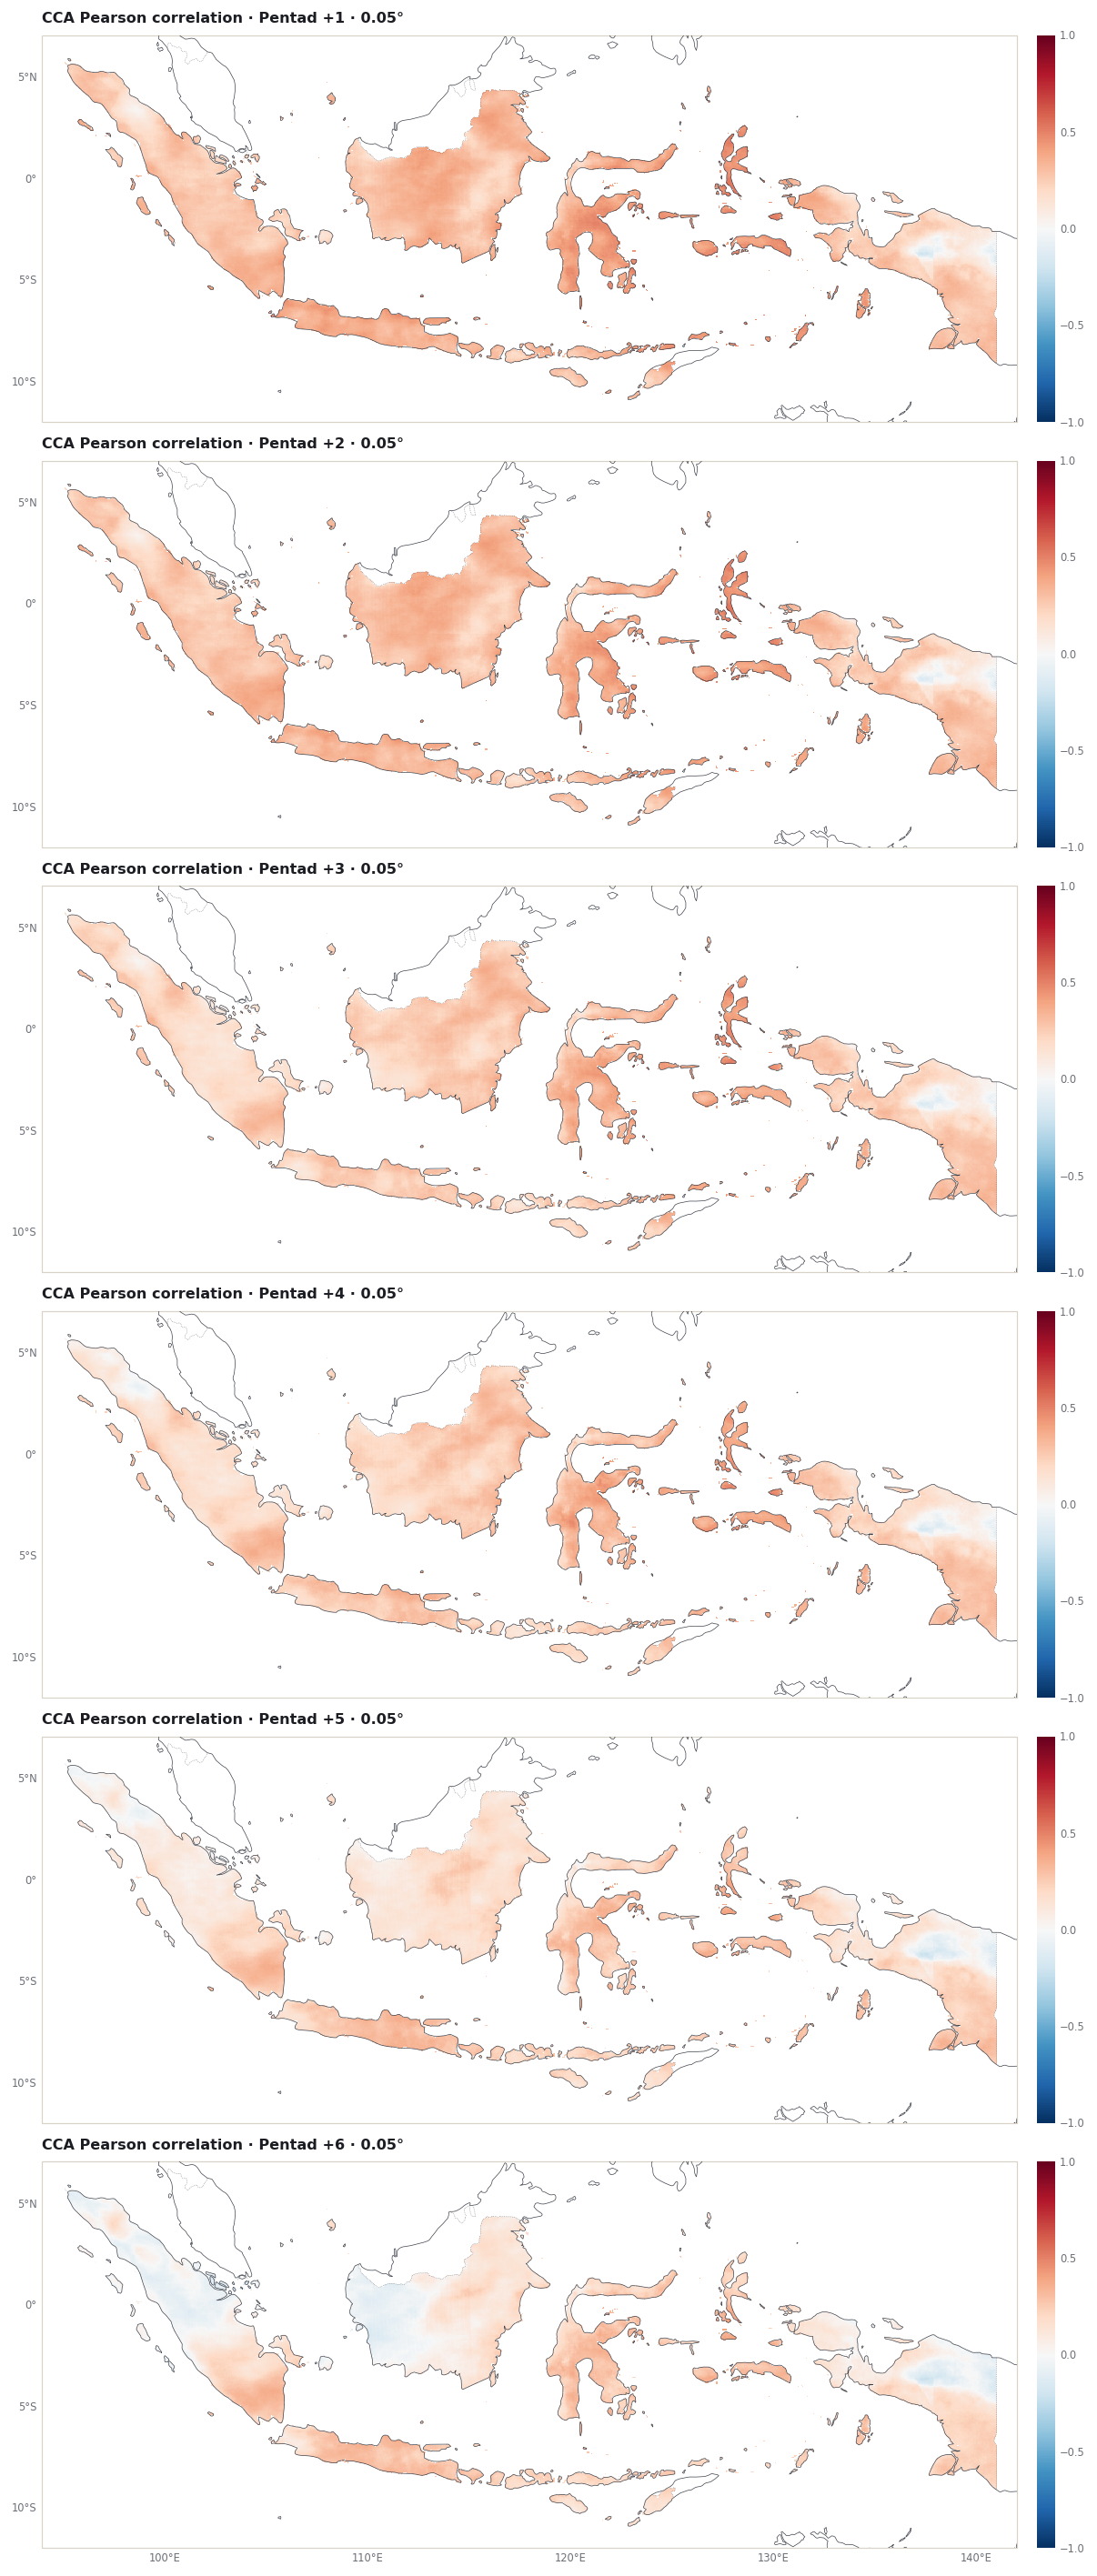

In [9]:
box = {"west": float(mask.X.min()) - .025, "east": float(mask.X.max()) + .025, "south": float(mask.Y.min()) - .025, "north": float(mask.Y.max()) + .025}
predictand_box = figures.extent_of(box)
fig, grid = figures.stacked([figures.map_height(predictand_box)] * len(leads))
for row, lead in enumerate(leads):
    ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == len(leads) - 1)
    image = figures.draw_field(ax, clean(results[lead, "CCA"].skill_pearson), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_title(f"CCA Pearson correlation · {lead_names[lead]} · 0.05°")
    figures.colorbar(fig, image, ax, "", ticks=[-1, -.5, 0, .5, 1])
fig.savefig(assets / "cca-pearson-by-lead.png")
plt.show()

## 7. The 2023 forecasts, as issued

Each issue date gives a forecast for the next six pentads. A forecast **total** is
the observed 2000-2018 mean for that calendar pentad plus the calibrated anomaly;
where that sum is negative it is set to zero, and the cell counts how often.

CPT also gives tercile probabilities. It defines the categories from the training
samples it was given, all 342 pentads together, so the observed category uses the
same definition: at each pixel, below the 33rd or above the 67th percentile of the
342 training anomalies (NumPy's `hazen` rule, as in
[chapter 5](../learn/05-probabilistic-forecasts.ipynb)).

In [10]:
test_T = targets.target.values[~train]
observed = obs.isel(T=~train).where(mask)
clim_2023 = y_clim.isel(T=~train)
observed_anom = y_anom.isel(T=~train)
lo, hi = np.quantile(y_anom.isel(T=train).values, [0.33, 0.67], axis=0, method="hazen")
lower = xr.DataArray(lo, coords={"Y": mask["Y"], "X": mask["X"]}, dims=("Y", "X"))
upper = lower.copy(data=hi)
category = xr.where(observed_anom < lower, 0, xr.where(observed_anom > upper, 2, 1)).where(observed_anom.notnull())

forecast, clipped = {}, {}
for (lead, method), r in results.items():
    anomaly = clean(r.deterministic).assign_coords(T=test_T)
    total = clim_2023 + anomaly
    clipped[lead, method] = int((total < 0).sum())
    probability = clean(r.probabilistic).assign_coords(T=test_T)
    most_likely = probability.fillna(-1).argmax("C").where(probability.notnull().all("C") & mask)
    forecast[lead, method] = dict(total=total.clip(min=0).where(mask), probability=probability, most_likely=most_likely,
                                  top=probability.max("C").where(mask))
print("Forecast totals below zero before clipping (pixel-pentads), CCA:", {lead: clipped[lead, "CCA"] for lead in leads},
      f"of {int(mask.sum()) * len(test_T):,} per lead")

issues = {}
for r in design[design.kind == "forecast"].sort_values(["issued", "lead"]).itertuples():
    issues.setdefault(r.issued, []).append((r.lead, r.target, r.days))
print(f"{len(issues)} issue dates in 2023, {min(issues):%d %b} to {max(issues):%d %b}; complete issues (all {len(leads)} leads): "
      f"{sum(len(v) == len(leads) for v in issues.values())}")
for s, items in list(issues.items())[6:8]:
    print(f"  issued {s:%d %b}: " + ", ".join(f"+{lead} = {t:%d %b} ({days} days)" for lead, t, days in items))

Forecast totals below zero before clipping (pixel-pentads), CCA: {1: 11766, 2: 8081, 3: 4877, 4: 3267, 5: 3758, 6: 5160} of 1,101,420 per lead
23 issue dates in 2023, 05 Sep to 25 Dec; complete issues (all 6 leads): 13
  issued 05 Oct: +1 = 06 Oct (5 days), +2 = 11 Oct (5 days), +3 = 16 Oct (5 days), +4 = 21 Oct (5 days), +5 = 26 Oct (6 days), +6 = 01 Nov (5 days)
  issued 10 Oct: +1 = 11 Oct (5 days), +2 = 16 Oct (5 days), +3 = 21 Oct (5 days), +4 = 26 Oct (6 days), +5 = 01 Nov (5 days), +6 = 06 Nov (5 days)


One issue date in full: the forecast issued on **31 October 2023** for the six
pentads of November, with the observation below each forecast. One column.

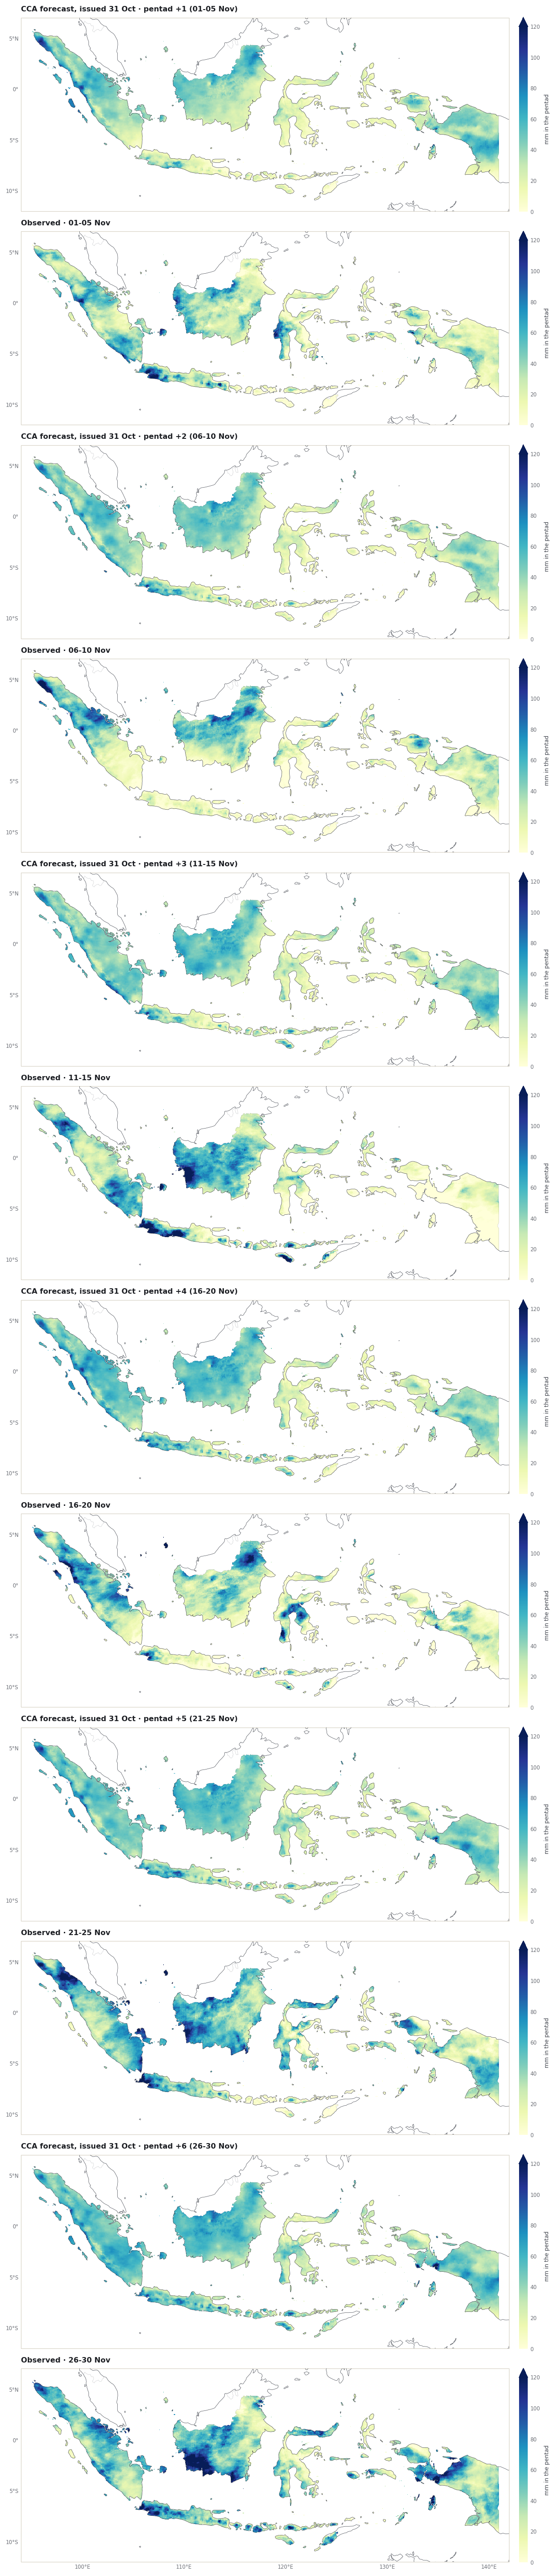

In [11]:
example = pd.Timestamp("2023-10-31")
fig, grid = figures.stacked([figures.map_height(predictand_box)] * (2 * len(leads)))
row = 0
for lead, target, days in issues[example]:
    end = target + pd.Timedelta(days=days - 1)
    for label, field in [(f"CCA forecast, issued 31 Oct · pentad +{lead} ({target:%d}-{end:%d %b})", forecast[lead, "CCA"]["total"].sel(T=target)),
                         (f"Observed · {target:%d}-{end:%d %b}", observed.sel(T=target))]:
        ax = figures.map_axes(fig, grid[row, 0], predictand_box, bottom_labels=row == 2 * len(leads) - 1)
        image = figures.draw_field(ax, field, cmap="YlGnBu", vmin=0, vmax=120)
        ax.set_title(label)
        figures.colorbar(fig, image, ax, "mm in the pentad", extend="max")
        row += 1
fig.savefig(assets / "issued-2023-10-31.png")
plt.show()

The same issue date in numbers: for each lead, the forecast and observed totals
averaged over Indonesia (area-weighted), the 2000-2018 mean, and how well the most
likely category matched what happened. One issue date is one outcome per lead, not a
skill estimate.

In [12]:
rows = []
for item in issues[example]:
    lead, target = item[0], item[1]
    days = item[2]
    end = target + pd.Timedelta(days=days - 1)
    obs_t, clim_t, cat_t = observed.sel(T=target), clim_2023.sel(T=target), category.sel(T=target)
    w = (weights * cat_t.notnull()).astype(float)
    shares = {name: float(w.where(cat_t == k, 0).sum() / w.sum() * 100) for k, name in enumerate(["below", "near", "above"])}
    for m in ["CCA", "PCR"]:
        f = forecast[lead, m]
        ml = f["most_likely"].sel(T=target)
        wm = w.where(ml.notnull(), 0)
        rows.append({"lead": lead, "name": lead_names[lead], "method": m, "target": f"{target:%d %b}-{end:%d %b %Y}",
                     "forecast mean (mm)": float(f["total"].sel(T=target).weighted(wm).mean()),
                     "observed mean (mm)": float(obs_t.weighted(wm).mean()),
                     "2000-2018 mean (mm)": float(clim_t.where(mask).weighted(wm).mean()),
                     "hit rate (%)": float(wm.where(ml == cat_t, 0).sum() / wm.sum() * 100),
                     "reference hit rate (%)": max(shares.values()),
                     **{f"observed {k} (%)": v for k, v in shares.items()},
                     **{f"forecast {name} (%)": float(wm.where(ml == k, 0).sum() / wm.sum() * 100)
                        for k, name in enumerate(["below", "near", "above"])}})
headline = pd.DataFrame(rows).set_index(["lead", "method"])
headline.round(1)

name              target  forecast mean (mm)  \
lead method                                                      
1    CCA     Pentad +1  01 Nov-05 Nov 2023                34.6   
     PCR     Pentad +1  01 Nov-05 Nov 2023                34.4   
2    CCA     Pentad +2  06 Nov-10 Nov 2023                35.9   
     PCR     Pentad +2  06 Nov-10 Nov 2023                35.6   
3    CCA     Pentad +3  11 Nov-15 Nov 2023                38.8   
     PCR     Pentad +3  11 Nov-15 Nov 2023                38.4   
4    CCA     Pentad +4  16 Nov-20 Nov 2023                41.1   
     PCR     Pentad +4  16 Nov-20 Nov 2023                40.9   
5    CCA     Pentad +5  21 Nov-25 Nov 2023                42.8   
     PCR     Pentad +5  21 Nov-25 Nov 2023                42.7   
6    CCA     Pentad +6  26 Nov-30 Nov 2023                46.6   
     PCR     Pentad +6  26 Nov-30 Nov 2023                46.5   

             observed mean (mm)  2000-2018 mean (mm)  hit rate (%)  \
lead method                                                          
1    CCA                   31.2                 44.4          44.9   
     PCR                   31.2                 44.4          44.3   
2    CCA                   29.1                 44.8          56.2   
     PCR                   29.1                 44.8          57.0   
3    CCA                   35.7                 48.4          45.6   
     PCR                   35.7                 48.4          45.2   
4    CCA                   32.1                 49.8          61.2   
     PCR                   32.1                 49.8          61.4   
5    CCA                   45.2                 47.4          37.5   
     PCR                   45.2                 47.4          36.6   
6    CCA                   49.0                 51.5          33.4   
     PCR                   49.0                 51.5          31.7   

             reference hit rate (%)  observed below (%)  observed near (%)  \
lead method                                                                  
1    CCA                       51.5                51.5               35.4   
     PCR                       51.5                51.5               35.4   
2    CCA                       57.0                57.0               33.1   
     PCR                       57.0                57.0               33.1   
3    CCA                       51.3                51.3               32.6   
     PCR                       51.3                51.3               32.6   
4    CCA                       65.7                65.7               22.1   
     PCR                       65.7                65.7               22.1   
5    CCA                       38.6                33.2               38.6   
     PCR                       38.6                33.2               38.6   
6    CCA                       36.9                34.6               36.9   
     PCR                       36.9                34.6               36.9   

             observed above (%)  forecast below (%)  forecast near (%)  \
lead method                                                              
1    CCA                   13.1                86.8                7.7   
     PCR                   13.1                87.4                7.0   
2    CCA                    9.9                84.9                8.8   
     PCR                    9.9                87.1                8.2   
3    CCA                   16.1                86.8                7.4   
     PCR                   16.1                88.4                6.4   
4    CCA                   12.1                85.4                8.3   
     PCR                   12.1                86.1                8.0   
5    CCA                   28.2                65.8               12.5   
     PCR                   28.2                67.1               12.7   
6    CCA                   28.4                68.0               11.8   
     PCR                   28.4                68.6      

Over all 18 pentads of October-December 2023, for each lead, scores over every pixel
and pentad (area-weighted):

- **Hit rate**: share where the most likely category was the one observed. The
  **reference** is the share of the most frequent observed category.
- **RPSS 2023**: ranked probability skill score against climatological odds
  (33/34/33%); above 0 is closer to what happened. Eighteen pentads of one season,
  not a skill estimate.
- **RMSE 2023**: error of the forecast totals in mm per pentad.

In [13]:
def rps(probability, cat):
    cumulative = probability.cumsum("C") / 100
    outcome = xr.concat([(cat <= k).astype(float) for k in range(3)], dim="C").assign_coords(C=probability["C"])
    return ((cumulative - outcome) ** 2).isel(C=slice(0, 2)).sum("C")


w3 = (weights * category.notnull()).astype(float)
reference = {name: float(w3.where(category == k, 0).sum() / w3.sum() * 100)
             for k, name in enumerate(["below normal", "near normal", "above normal"])}
rows = []
for (lead, method), f in forecast.items():
    w = w3.where(f["most_likely"].notnull(), 0)
    climatology = xr.DataArray([33.0, 34.0, 33.0], dims="C", coords={"C": f["probability"]["C"]}).broadcast_like(f["probability"])
    rows.append({"lead": lead, "name": lead_names[lead], "method": method,
                 "hit rate (%)": float(w.where(f["most_likely"] == category, 0).sum() / w.sum() * 100),
                 "reference hit rate (%)": max(reference.values()),
                 "RPSS 2023": float(1 - rps(f["probability"], category).weighted(w).mean()
                                    / rps(climatology, category).weighted(w).mean()),
                 "RMSE 2023 (mm)": float(np.sqrt(((f["total"] - observed) ** 2).weighted(w).mean())),
                 "mean forecast (mm)": float(f["total"].weighted(w).mean()),
                 "observed mean (mm)": float(observed.weighted(w).mean()),
                 **{f"forecast {name} (%)": float(w.where(f["most_likely"] == k, 0).sum() / w.sum() * 100)
                    for k, name in enumerate(["below", "near", "above"])}})
forecast_2023 = pd.DataFrame(rows).set_index(["lead", "method"]).sort_index()
print("Observed categories, share of area x pentads (%):", {k: round(v, 1) for k, v in reference.items()})
forecast_2023.round(2)

Observed categories, share of area x pentads (%): {'below normal': 48.2, 'near normal': 32.9, 'above normal': 18.9}


name  hit rate (%)  reference hit rate (%)  RPSS 2023  \
lead method                                                               
1    CCA     Pentad +1         44.65                   48.23       0.08   
     PCR     Pentad +1         45.02                   48.23       0.08   
2    CCA     Pentad +2         43.50                   48.23       0.07   
     PCR     Pentad +2         43.59                   48.23       0.07   
3    CCA     Pentad +3         40.88                   48.23       0.04   
     PCR     Pentad +3         41.00                   48.23       0.04   
4    CCA     Pentad +4         39.39                   48.23       0.03   
     PCR     Pentad +4         39.69                   48.23       0.03   
5    CCA     Pentad +5         42.57                   48.23       0.05   
     PCR     Pentad +5         42.30                   48.23       0.05   
6    CCA     Pentad +6         40.05                   48.23       0.02   
     PCR     Pentad +6         40.40                   48.23       0.03   

             RMSE 2023 (mm)  mean forecast (mm)  observed mean (mm)  \
lead method                                                           
1    CCA              25.20               41.25               35.95   
     PCR              25.23               41.16               35.95   
2    CCA              25.34               41.25               35.95   
     PCR              25.46               41.15               35.95   
3    CCA              25.97               42.14               35.95   
     PCR              26.02               41.88               35.95   
4    CCA              26.29               42.84               35.95   
     PCR              26.39               42.77               35.95   
5    CCA              25.71               41.87               35.95   
     PCR              25.88               41.81               35.95   
6    CCA              26.29               42.16               35.95   
     PCR              26.30               42.08               35.95   

             forecast below (%)  forecast near (%)  forecast above (%)  
lead method                                                             
1    CCA                  63.40              11.76               24.85  
     PCR                  63.71              11.48               24.81  
2    CCA                  61.10              12.79               26.11  
     PCR                  61.78              12.60               25.63  
3    CCA                  59.21              13.76               27.03  
     PCR                  60.85              13.28               25.87  
4    CCA                  55.64              14.12               30.23  
     PCR                  56.54              13.73               29.72  
5    CCA                  62.61              12.12               25.28  
     PCR                  63.38              11.95               24.67  
6    CCA                  62.51              12.23               25.26  
     PCR                  63.13              12.33               24.55

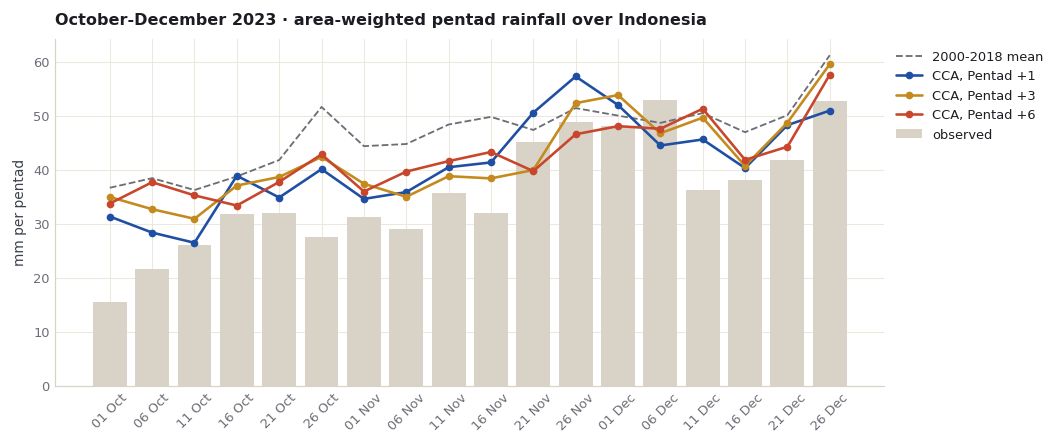

In [14]:
labels = [f"{pd.Timestamp(t):%d %b}" for t in test_T]
observed_series = observed.weighted(weights).mean(("Y", "X"))
clim_series = clim_2023.where(mask).weighted(weights).mean(("Y", "X"))
series_leads = [1, 3, 6]
fig, ax = plt.subplots(figsize=(figures.MAP_WIDTH, 3.9), layout="constrained")
x = np.arange(len(test_T))
ax.bar(x, observed_series, color=figures.LINE, label="observed")
ax.plot(x, clim_series, color=figures.MUTED, linestyle="--", linewidth=1.2, label="2000-2018 mean")
for lead, colour in zip(series_leads, [figures.ACCENT, figures.GOLD, figures.MARK]):
    s = forecast[lead, "CCA"]["total"].weighted(weights).mean(("Y", "X"))
    ax.plot(x, s, "o-", color=colour, markersize=4, label=f"CCA, {lead_names[lead]}")
ax.set_xticks(x, labels, rotation=45)
ax.set_ylabel("mm per pentad")
ax.set_title("October-December 2023 · area-weighted pentad rainfall over Indonesia")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.savefig(assets / "ond-2023-pentad-series.png")
plt.show()

## 8. Save the results

Tables and figures for the story page, a NetCDF file of the skill maps, and the
fields of the interactive page: one small gzip-compressed binary file per map,
integers at a stated scale, stored only at the Indonesian pixels in the order of a
shared pixel list, read by the page only when a view needs them.

In [15]:
data_dir = repo / "docs/data/pentad-leads-2023"
data_dir.mkdir(parents=True, exist_ok=True)
skill_by_lead.round(4).to_csv(data_dir / "skill-by-lead.csv")
headline.round(4).to_csv(data_dir / f"issued-{example:%Y-%m-%d}.csv")
forecast_2023.round(4).to_csv(data_dir / "ond-2023-pentad-forecasts.csv")
design.assign(**{c: design[c].dt.date for c in ["target", "end", "issued", "start"]}).to_csv(data_dir / "lead-design.csv", index=False)
area_rows = {"start": [str(pd.Timestamp(t).date()) for t in test_T], "observed": observed_series.values, "mean_2000_2018": clim_series.values}
for lead in leads:
    area_rows[f"cca_total_lead{lead}"] = forecast[lead, "CCA"]["total"].weighted(weights).mean(("Y", "X")).values
pd.DataFrame(area_rows).round(3).to_csv(data_dir / "ond-2023-area-totals.csv", index=False)
summary = {"target": "October-December 2023, pentads", "model": "GEFSv12 (IRI SubX GEFSv12_CPC)", "grid": "CHIRPS v3.0 native 0.05 degree",
           "issue_rule": "issued on the last day of a pentad, 00 UTC run; forecasts pentads +1 to +6",
           "training_windows_days": {str(k): list(v) for k, v in pentads.WINDOWS.items()},
           "training_years": [training_years[0], training_years[-1]], "training_pentads_per_lead": int(train.sum()),
           "pixels": int(mask.sum()), "cross_validation_window": settings["crossvalidation_window"],
           "settings": {k: str(v) for k, v in cca_settings.items()},
           "observed_category_percent_2023": {k: round(v, 2) for k, v in reference.items()},
           "fit_minutes": {f"{lead}-{m}": round(r.attrs["fit_seconds"] / 60, 1) for (lead, m), r in results.items()},
           "clipped_pixel_pentads": {f"{lead}-{m}": n for (lead, m), n in clipped.items()}}
(data_dir / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")
maps = xr.Dataset()
for lead in leads:
    for m in ["CCA", "PCR"]:
        maps[f"{m.lower()}_pearson_lead{lead}"] = clean(results[lead, m].skill_pearson).drop_vars(
            [c for c in results[lead, m].skill_pearson.coords if c not in ("Y", "X")], errors="ignore").astype("float32")
    maps[f"raw_pearson_lead{lead}"] = raw_pearson[lead].astype("float32")
_ = save_netcdf(maps, data_dir / "pentad-leads-2023-skill-maps.nc", overwrite=True,
            metadata={"note": "Pentad rainfall, GEFSv12 pentads +1 to +6: cross-validated correlation 2000-2018 at 0.05 degree"})

In [16]:
# Interactive fields: one gzip-compressed binary file per map
field_dir = assets / "fields"
field_dir.mkdir(exist_ok=True)
for old in field_dir.glob("*"):
    old.unlink()
flat = np.flatnonzero(mask.transpose("Y", "X").values.ravel())          # row 0 = northernmost pixel row
n = len(flat)
lead_key = {lead: f"pentad{lead}" for lead in leads}


def at_pixels(a):
    return np.asarray(a.transpose("Y", "X").values, dtype="float64").ravel()[flat]


def encode(values, kind, scale):
    v = np.round(values * scale)
    if kind == "i16":
        return np.where(np.isfinite(v), np.clip(v, -32767, 32767), -32768).astype("<i2").tobytes()
    if kind == "u16":
        return np.where(np.isfinite(v), np.clip(v, 0, 65534), 65535).astype("<u2").tobytes()
    return np.where(np.isfinite(v), np.clip(v, 0, 254), 255).astype("u1").tobytes()


def write(name, parts):
    (field_dir / f"{name}.bin.gz").write_bytes(gzip.compress(b"".join(encode(*p) for p in parts), 9, mtime=0))


(assets / "pixels.bin").write_bytes(flat.astype("<i4").tobytes())
for lead in leads:
    for m in ["CCA", "PCR"]:
        write(f"skill-{m}-pearson-{lead_key[lead]}", [(at_pixels(clean(results[lead, m].skill_pearson)), "i16", 1000)])
        write(f"skill-{m}-twoafc-{lead_key[lead]}", [(at_pixels(clean(results[lead, m].skill_two_alternative_forced_choice)), "i16", 10)])
    write(f"skill-raw-pearson-{lead_key[lead]}", [(at_pixels(raw_pearson[lead]), "i16", 1000)])
days_of = dict(zip(targets.target, targets.days))
for t in test_T:
    stamp = f"{pd.Timestamp(t):%Y-%m-%d}"
    write(f"obs-{days_of[pd.Timestamp(t)]}-{stamp}", [(at_pixels(observed.sel(T=t)), "u16", 10), (at_pixels(clim_2023.sel(T=t).where(mask)), "u16", 10),
                                                       (at_pixels(category.sel(T=t)), "u8", 1)])
for (lead, m), f in forecast.items():
    for t in test_T:
        stamp = f"{pd.Timestamp(t):%Y-%m-%d}"
        write(f"fc-{lead_key[lead]}-{m}-{stamp}", [(at_pixels(f["total"].sel(T=t)), "u16", 10), (at_pixels(f["most_likely"].sel(T=t)), "u8", 1),
                                                   (at_pixels(f["top"].sel(T=t)), "u8", 1)])


def records(frame):
    return [{k: (None if isinstance(v, float) and not np.isfinite(v) else v) for k, v in row.items()}
            for row in frame.to_dict(orient="records")]


top = float(np.ceil(np.nanpercentile(np.concatenate([observed.values.ravel()] + [forecast[k]["total"].values.ravel() for k in forecast]), 99) / 25) * 25)
manifest = {
    "grid": {"west": round(float(mask.X.min()) - .025, 3), "north": round(float(mask.Y.max()) + .025, 3), "step": 0.05,
             "nx": int(mask.sizes["X"]), "ny": int(mask.sizes["Y"]), "pixels": n},
    "leads": leads, "leadKeys": [lead_key[lead] for lead in leads], "leadNames": [lead_names[lead] for lead in leads],
    "methods": ["CCA", "PCR"], "rawName": "raw GEFS", "training": "2000-2018",
    "sample": "the 342 training pentads of 2000-2018", "cellText": f"Indonesia's {n:,} pixels at 0.05°",
    "layout": {"skill": [["value", "i16"]], "obs": [["total", "u16", 10], ["mean", "u16", 10], ["category", "u8", 1]],
               "fc": [["total", "u16", 10], ["category", "u8", 1], ["probability", "u8", 1]]},
    "scales": {"pearson": 1000, "twoafc": 10},
    "rainMax": {"5": top, "6": top, "3": top, "4": top}, "rainLegend": "mm in the pentad", "axisDays": 35,
    "timelineTitle": "the next six pentads",
    "timelineHint": "Issued at 00 UTC on the last day of a pentad. Bars are the target pentads in days after the issue date; hover for dates.",
    "mapsHint": "Pentad +1 at the top. Totals are the 2000-2018 mean for that calendar pentad plus the calibrated anomaly; categories follow CPT's terciles of the training anomalies.",
    "seriesHint": "Bars: observed. Dashed: 2000-2018 mean. Lines: CCA forecast totals made one, three and six pentads ahead.",
    "issues": [{"issued": f"{s:%Y-%m-%d}", "label": f"{s:%d %b %Y}",
                "targets": [{"lead": lead_key[lead], "start": f"{t:%Y-%m-%d}", "days": int(days)} for lead, t, days in items]}
               for s, items in issues.items()],
    "skillTable": records(skill_by_lead.reset_index().round(4)),
    "scores2023": records(forecast_2023.reset_index().round(3)),
    "headline": {"issued": f"{example:%Y-%m-%d}", "rows": records(headline.reset_index().round(3))},
    "series": pd.DataFrame(area_rows).round(2).to_dict(orient="list"),
    "seriesLeads": [lead_key[lead] for lead in series_leads], "seriesUnit": "mm per pentad",
    "seriesTitle": "October-December 2023 · area-weighted pentad rainfall over Indonesia",
}
(assets / "manifest.json").write_text(json.dumps(manifest, separators=(",", ":"), allow_nan=False) + "\n")
sizes = sorted(p.stat().st_size for p in field_dir.iterdir())
print(f"{n:,} pixels; {len(sizes)} field files, {sum(sizes) / 1e6:.1f} MB in total (largest {sizes[-1] / 1e3:.0f} kB); "
      f"manifest {(assets / 'manifest.json').stat().st_size / 1e3:.0f} kB; colour scale up to {top:.0f} mm")
for f in sorted(data_dir.iterdir()) + sorted(p for p in assets.iterdir() if p.is_file()):
    print(f"{f.relative_to(repo)}  ({f.stat().st_size / 1000:.0f} kB)")

61,190 pixels; 264 field files, 31.0 MB in total (largest 175 kB); manifest 20 kB; colour scale up to 100 mm
docs/data/pentad-leads-2023/issued-2023-10-31.csv  (2 kB)
docs/data/pentad-leads-2023/lead-design.csv  (146 kB)
docs/data/pentad-leads-2023/ond-2023-area-totals.csv  (1 kB)
docs/data/pentad-leads-2023/ond-2023-pentad-forecasts.csv  (1 kB)
docs/data/pentad-leads-2023/pentad-leads-2023-skill-maps.nc  (4033 kB)
docs/data/pentad-leads-2023/skill-by-lead.csv  (1 kB)
docs/data/pentad-leads-2023/summary.json  (2 kB)
docs/assets/pentad-leads-2023/cca-pearson-by-lead.png  (1638 kB)
docs/assets/pentad-leads-2023/issued-2023-10-31.png  (3872 kB)
docs/assets/pentad-leads-2023/manifest.json  (20 kB)
docs/assets/pentad-leads-2023/ond-2023-pentad-series.png  (123 kB)
docs/assets/pentad-leads-2023/pixels.bin  (245 kB)
docs/assets/pentad-leads-2023/skill-by-lead.png  (90 kB)


## References {.unnumbered .reference-section}

1. IRI Data Library. *SubX EMC GEFSv12_CPC* (hindcast and forecast precipitation). <https://iridl.ldeo.columbia.edu/SOURCES/.Models/.SubX/.EMC/.GEFSv12_CPC/> Browsing Data Library pages requires signing in (checked 10 November 2026); PyCPT's data requests in this tutorial succeeded without a key.
2. Guan, H., Zhu, Y., Sinsky, E., et al. (2022). GEFSv12 reforecast dataset for supporting subseasonal and hydrometeorological applications. *Monthly Weather Review*, 150(3), 647-665. <https://doi.org/10.1175/MWR-D-21-0245.1>
3. Climate Hazards Center, UC Santa Barbara. *CHIRPS: Rainfall Estimates from Rain Gauge and Satellite Observations* (CHIRPS version 3.0 page). <https://www.chc.ucsb.edu/data/chirps3>
4. Funk, C., Peterson, P., Landsfeld, M., et al. (2014). *A quasi-global precipitation time series for drought monitoring*. U.S. Geological Survey Data Series 832. <https://doi.org/10.3133/ds832>
5. Climate Hazards Center. *README for CHIRPS v3.0* (products from pentadal to annual; preliminary data two days after each pentad, on the 2nd, 7th, 12th, 17th, 22nd and 27th). <https://data.chc.ucsb.edu/products/CHIRPS/v3.0/README-CHIRPSv3.0.txt>
6. Climate Hazards Center. *Information about CHIRPS Daily Precipitation* (CHIRPS v3.0 daily readme). <https://data.chc.ucsb.edu/products/CHIRPS/v3.0/daily/readme.txt>
7. Google Earth Engine Data Catalog. *CHIRPS v3.0 Pentad* (`UCSB-CHC/CHIRPS/V3/PENTAD`, mm per pentad). <https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHC_CHIRPS_V3_PENTAD>
8. IRI. *PyCPT 2.10.4 source: `pycpt/src/cptcore/functional/cca.py`* (`canonical_correlation_analysis`). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/cptcore/functional/cca.py>
9. IRI. *PyCPT 2.10.4 source: `pycpt/src/cptextras/redate.py`* (`redate`). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/cptextras/redate.py>
10. Natural Earth. *Admin 0: Countries*, 1:10m cultural vectors. <https://www.naturalearthdata.com/downloads/10m-cultural-vectors/10m-admin-0-countries/>
11. Shapely. *shapely.contains_xy*. <https://shapely.readthedocs.io/en/stable/reference/shapely.contains_xy.html>
12. NumPy. *numpy.quantile* (NumPy manual). <https://numpy.org/doc/stable/reference/generated/numpy.quantile.html>
13. Mason, S. J., and Weigel, A. P. (2009). A generic forecast verification framework for administrative purposes. *Monthly Weather Review*, 137(1), 331-349. <https://doi.org/10.1175/2008MWR2553.1>
14. Epstein, E. S. (1969). A scoring system for probability forecasts of ranked categories. *Journal of Applied Meteorology*, 8(6), 985-987. <https://doi.org/10.1175/1520-0450(1969)008%3C0985:ASSFPF%3E2.0.CO;2>
15. Barnston, A. G., and van den Dool, H. M. (1993). A degeneracy in cross-validated skill in regression-based forecasts. *Journal of Climate*, 6(5), 963-977. <https://doi.org/10.1175/1520-0442(1993)006%3C0963:ADICVS%3E2.0.CO;2>
16. SciTools. *Cartopy* (documentation). <https://scitools.org.uk/cartopy/docs/latest/>